# RQ6 — How strongly does protein representation determine generalization?

## Scientific question

**Do pretrained protein representations provide consistently better and more robust functional generalization than one-hot sequence encoding and compact physicochemical descriptors across the complete `R×S` landscape?**

Representation comparisons are evaluated within the matched unit:

\[
\text{task}\times R\times S\times\text{algorithm}
\]

so every representation comparison uses the same biological task, train/test condition, and classifier.

The current supervised benchmark contains four frozen predictive representations:

- `roxy_48`
- `onehot_1024`
- `esm2_t6_8m`
- `esm2_t30_150m`

RQ6 focuses on **representation quality as a generalization factor**.  
The specific ESM2 capacity question (`T6` versus `T30`) is quantified here but reserved for deeper interpretation in RQ7.

## Scope

RQ6 asks only the questions needed for the paper:

1. Which representations perform best overall?
2. Are representation gains consistent in matched comparisons?
3. Are gains task-dependent?
4. Do representation advantages become larger in stricter `R/S` regimes?
5. Which representations win most often across native benchmark cells?
6. Which representations have the strongest worst-case performance?
7. Which representations are most robust to redundancy reduction and remote-homology separation?
8. Are conclusions preserved with AP skill and multiclass macro-F1?

No compute-adjusted ranking is performed here, and classifier-specific mechanisms are deferred to the algorithm RQ.

In [1]:
from pathlib import Path
from itertools import combinations
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 300)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

BINARY_TASKS = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

REP_ORDER_PREFERRED = [
    "roxy_48",
    "onehot_1024",
    "esm2_t6_8m",
    "esm2_t30_150m",
]

REP_LABEL = {
    "roxy_48": "Roxy",
    "onehot_1024": "One-hot",
    "esm2_t6_8m": "ESM2-T6",
    "esm2_t30_150m": "ESM2-T30",
}

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/analysis_supervised/stage12b").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate project root containing Stage12A and Stage12B."
    )

ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
STAGE12B = ROOT / "results/analysis_supervised/stage12b"
CACHE_DIR = ROOT / "results/analysis_supervised/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass


In [2]:
master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

rep_pairwise_raw = pd.read_csv(
    STAGE12B / "representation_pairwise_deltas.tsv",
    sep="\t",
    low_memory=False,
)

robustness = pd.read_csv(
    STAGE12B / "robustness_summary.tsv",
    sep="\t",
    low_memory=False,
)

REPS = [
    r for r in REP_ORDER_PREFERRED
    if r in master["representation"].unique()
]

# Include unexpected representations rather than silently dropping them.
REPS += [
    r for r in sorted(master["representation"].unique())
    if r not in REPS
]

print("Experiment families:", len(master))
print("Representations:", REPS)
print("Tasks:", sorted(master["task"].unique()))
print("Algorithms:", sorted(master["algorithm"].unique()))

coverage = (
    master.groupby(["task", "R", "S", "algorithm"])
    ["representation"]
    .nunique()
    .rename("n_representations")
    .reset_index()
)

display(coverage["n_representations"].value_counts().sort_index().to_frame("n_cells"))

assert coverage["n_representations"].eq(len(REPS)).all(), (
    "Representation coverage is incomplete in one or more matched cells."
)

N_MATCHED_CELLS = len(coverage)
print("Matched task×R×S×algorithm cells:", N_MATCHED_CELLS)
print(
    "Expected representation pairs per metric:",
    N_MATCHED_CELLS * len(list(combinations(REPS, 2))),
)

Experiment families: 2240
Representations: ['roxy_48', 'onehot_1024', 'esm2_t6_8m', 'esm2_t30_150m']
Tasks: ['global_easy', 'global_hard', 'global_mixed', 'multiclass_clean', 'subtype_depolymerase', 'subtype_endolysin', 'subtype_val']
Algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']


,n_cells
n_representations,
4,560


Matched task×R×S×algorithm cells: 560
Expected representation pairs per metric: 3360


## 1. AP skill

For binary tasks, normalize average precision relative to test prevalence:

\[
AP_{skill}
=
\frac{AP-\pi}{1-\pi},
\]

where \(\pi\) is positive-class prevalence.

In [3]:
def detect_prevalence(df):
    for c in [
        "test_prevalence",
        "prevalence",
        "positive_prevalence",
        "class_prevalence",
    ]:
        if c in df.columns:
            return pd.to_numeric(df[c], errors="coerce"), c

    if {"n_positive", "n_test"} <= set(df.columns):
        return (
            pd.to_numeric(df["n_positive"], errors="coerce")
            / pd.to_numeric(df["n_test"], errors="coerce")
        ), "derived_from_n_positive_n_test"

    if {"tp", "fn", "tn", "fp"} <= set(df.columns):
        pos = (
            pd.to_numeric(df["tp"], errors="coerce")
            + pd.to_numeric(df["fn"], errors="coerce")
        )
        n = (
            pos
            + pd.to_numeric(df["tn"], errors="coerce")
            + pd.to_numeric(df["fp"], errors="coerce")
        )
        return pos / n, "derived_from_confusion_counts"

    return pd.Series(np.nan, index=df.index), None

prev, prev_source = detect_prevalence(master)
master["prevalence_for_ap"] = prev

if "ap" in master.columns:
    denom = 1.0 - master["prevalence_for_ap"]
    master["ap_skill"] = np.where(
        denom > 0,
        (master["ap"] - master["prevalence_for_ap"]) / denom,
        np.nan,
    )

print("Prevalence source:", prev_source)

Prevalence source: prevalence


# 2. Overall predictive performance by representation

In [4]:
overall_rep = (
    master.groupby("representation")
    .agg(
        n=("mcc", "size"),
        mcc_mean=("mcc", "mean"),
        mcc_median=("mcc", "median"),
        mcc_q25=("mcc", lambda x: x.quantile(0.25)),
        mcc_q75=("mcc", lambda x: x.quantile(0.75)),
        mcc_min=("mcc", "min"),
        mcc_max=("mcc", "max"),
    )
    .reindex(REPS)
)

display(overall_rep)

,n,mcc_mean,mcc_median,mcc_q25,mcc_q75,mcc_min,mcc_max
representation,,,,,,,
roxy_48,560,0.649787,0.675438,0.555661,0.800675,0.000000,0.926082
onehot_1024,560,0.463568,0.496018,0.326372,0.675553,0.000000,0.872823
esm2_t6_8m,560,0.798397,0.828667,0.751310,0.885474,0.000000,0.958064
esm2_t30_150m,560,0.882970,0.902239,0.866590,0.929704,0.377688,0.964477


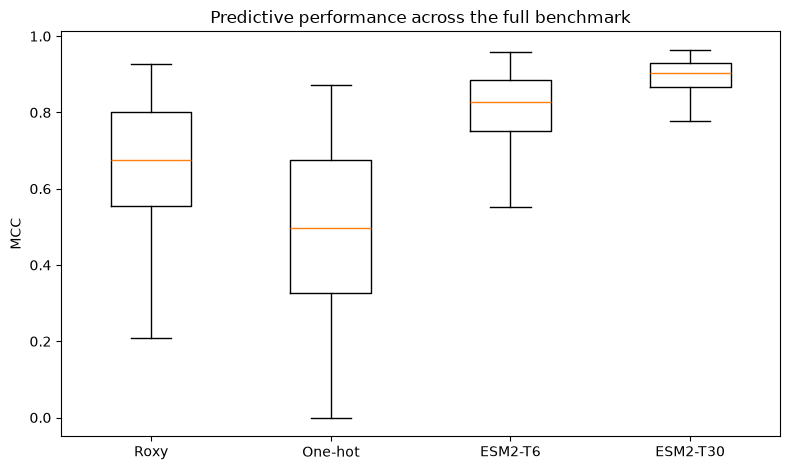

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.8))

data = [
    master.loc[
        master["representation"].eq(rep),
        "mcc",
    ].dropna().to_numpy()
    for rep in REPS
]

ax.boxplot(
    data,
    tick_labels=[REP_LABEL.get(r, r) for r in REPS],
    showfliers=False,
)
ax.set_ylabel("MCC")
ax.set_title("Predictive performance across the full benchmark")
plt.tight_layout()
plt.show()

Raw pooled distributions are descriptive only.  
The primary evidence comes from **paired representation comparisons within identical benchmark cells**.

# 3. Reconstruct all paired representation contrasts

In [6]:
def paired_representation_table(df, metric):
    rows = []

    group_cols = ["task", "R", "S", "algorithm"]

    for keys, grp in df.groupby(group_cols):
        task, r, s, alg = keys

        lookup = dict(
            zip(
                grp["representation"],
                pd.to_numeric(grp[metric], errors="coerce"),
            )
        )

        for rep_a, rep_b in combinations(REPS, 2):
            if (
                rep_a not in lookup
                or rep_b not in lookup
                or pd.isna(lookup[rep_a])
                or pd.isna(lookup[rep_b])
            ):
                continue

            rows.append(
                {
                    "task": task,
                    "R": r,
                    "S": s,
                    "algorithm": alg,
                    "metric": metric,
                    "representation_A": rep_a,
                    "representation_B": rep_b,
                    "value_A": float(lookup[rep_a]),
                    "value_B": float(lookup[rep_b]),
                    "delta_B_minus_A": (
                        float(lookup[rep_b])
                        - float(lookup[rep_a])
                    ),
                }
            )

    return pd.DataFrame(rows)

rep_mcc = paired_representation_table(master, "mcc")

print("Paired MCC contrasts:", len(rep_mcc))
display(rep_mcc.head())

Paired MCC contrasts: 3360


,task,R,S,algorithm,metric,representation_A,representation_B,value_A,value_B,delta_B_minus_A
0,global_easy,30,30,KNN,mcc,roxy_48,onehot_1024,0.569305,0.339250,-0.230056
1,global_easy,30,30,KNN,mcc,roxy_48,esm2_t6_8m,0.569305,0.756290,0.186985
2,global_easy,30,30,KNN,mcc,roxy_48,esm2_t30_150m,0.569305,0.887662,0.318357
3,global_easy,30,30,KNN,mcc,onehot_1024,esm2_t6_8m,0.339250,0.756290,0.417041
4,global_easy,30,30,KNN,mcc,onehot_1024,esm2_t30_150m,0.339250,0.887662,0.548412


# 4. Pairwise ΔMCC, win/tie/loss, and consistency

In [7]:
PAIR_TOL = 0.01

pair_summary_rows = []

for (a, b), grp in rep_mcc.groupby(
    ["representation_A", "representation_B"]
):
    d = grp["delta_B_minus_A"].dropna()

    pair_summary_rows.append(
        {
            "representation_A": a,
            "representation_B": b,
            "comparison": (
                f"{REP_LABEL.get(b,b)} − {REP_LABEL.get(a,a)}"
            ),
            "n": len(d),
            "mean_delta": d.mean(),
            "median_delta": d.median(),
            "q25": d.quantile(0.25),
            "q75": d.quantile(0.75),
            "fraction_B_better": (d > PAIR_TOL).mean(),
            "fraction_tie": (d.abs() <= PAIR_TOL).mean(),
            "fraction_A_better": (d < -PAIR_TOL).mean(),
            "fraction_delta_positive": (d > 0).mean(),
        }
    )

pair_summary = (
    pd.DataFrame(pair_summary_rows)
    .sort_values("median_delta", ascending=False)
)

display(pair_summary)

,representation_A,representation_B,comparison,n,mean_delta,median_delta,q25,q75,fraction_B_better,fraction_tie,fraction_A_better,fraction_delta_positive
1,onehot_1024,esm2_t30_150m,ESM2-T30 − One-hot,560,0.419403,0.411692,0.222810,0.539046,1.000000,0.000000,0.000000,1.000000
2,onehot_1024,esm2_t6_8m,ESM2-T6 − One-hot,560,0.334830,0.291002,0.194664,0.418898,0.989286,0.008929,0.001786,0.991071
3,roxy_48,esm2_t30_150m,ESM2-T30 − Roxy,560,0.233184,0.234556,0.097312,0.309108,1.000000,0.000000,0.000000,1.000000
4,roxy_48,esm2_t6_8m,ESM2-T6 − Roxy,560,0.148611,0.132891,0.081292,0.192532,0.982143,0.007143,0.010714,0.983929
0,esm2_t6_8m,esm2_t30_150m,ESM2-T30 − ESM2-T6,560,0.084573,0.076907,0.019407,0.124788,0.828571,0.151786,0.019643,0.928571
5,roxy_48,onehot_1024,One-hot − Roxy,560,-0.186219,-0.160737,-0.261376,-0.074025,0.085714,0.014286,0.900000,0.091071


A representation advantage is strongest when it has:

- positive paired median ΔMCC;
- a large fraction of positive deltas;
- a large win fraction after applying the small `0.01 MCC` practical tie region.

# 5. Direct T30 comparisons against each alternative

In [8]:
T30 = "esm2_t30_150m"

t30_rows = []

if T30 in REPS:
    for comparator in [r for r in REPS if r != T30]:
        rows = []

        for keys, grp in master.groupby(
            ["task", "R", "S", "algorithm"]
        ):
            task, r, s, alg = keys
            lookup = dict(zip(grp["representation"], grp["mcc"]))

            if comparator in lookup and T30 in lookup:
                rows.append(
                    {
                        "task": task,
                        "R": r,
                        "S": s,
                        "algorithm": alg,
                        "comparator": comparator,
                        "delta_mcc_T30_minus_comparator": (
                            lookup[T30] - lookup[comparator]
                        ),
                    }
                )

        t30_rows.extend(rows)

t30_deltas = pd.DataFrame(t30_rows)

display(
    t30_deltas.groupby("comparator")[
        "delta_mcc_T30_minus_comparator"
    ]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

,count,mean,median,std,min,max
comparator,,,,,,
esm2_t6_8m,560,0.084573,0.076907,0.081199,-0.086975,0.533816
onehot_1024,560,0.419403,0.411692,0.217743,0.080443,0.925583
roxy_48,560,0.233184,0.234556,0.149645,0.025585,0.784253


In [9]:
display(
    t30_deltas.groupby("comparator")[
        "delta_mcc_T30_minus_comparator"
    ]
    .agg(
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_gt_001=lambda x: (x > 0.01).mean(),
        fraction_negative=lambda x: (x < 0).mean(),
    )
)

,fraction_positive,fraction_gt_001,fraction_negative
comparator,,,
esm2_t6_8m,0.928571,0.828571,0.066071
onehot_1024,1.000000,1.000000,0.000000
roxy_48,1.000000,1.000000,0.000000


# 6. Representation effects by biological task

In [10]:
task_rep = (
    master.groupby(["task", "representation"])
    .agg(
        mcc_mean=("mcc", "mean"),
        mcc_median=("mcc", "median"),
        mcc_min=("mcc", "min"),
    )
    .reset_index()
)

display(
    task_rep.pivot(
        index="task",
        columns="representation",
        values="mcc_median",
    ).reindex(columns=REPS)
)

representation,roxy_48,onehot_1024,esm2_t6_8m,esm2_t30_150m
task,,,,
global_easy,0.644255,0.430960,0.797830,0.918036
global_hard,0.852161,0.766787,0.930180,0.940280
global_mixed,0.641811,0.417696,0.791804,0.912234
multiclass_clean,0.775576,0.656324,0.844689,0.877199
subtype_depolymerase,0.816482,0.640043,0.885816,0.907828
subtype_endolysin,0.592380,0.351786,0.765725,0.910601
subtype_val,0.332673,0.000000,0.627972,0.793975


In [11]:
if len(t30_deltas):
    t30_by_task = (
        t30_deltas.groupby(["task", "comparator"])[
            "delta_mcc_T30_minus_comparator"
        ]
        .agg(
            mean="mean",
            median="median",
            fraction_positive=lambda x: (x > 0).mean(),
        )
        .reset_index()
    )

    display(t30_by_task)

,task,comparator,mean,median,fraction_positive
0,global_easy,esm2_t6_8m,0.113703,0.113017,1.0000
1,global_easy,onehot_1024,0.489926,0.469211,1.0000
2,global_easy,roxy_48,0.283498,0.266704,1.0000
3,global_hard,esm2_t6_8m,0.007452,0.007816,0.8000
4,global_hard,onehot_1024,0.169416,0.170932,1.0000
5,global_hard,roxy_48,0.083342,0.082773,1.0000
6,global_mixed,esm2_t6_8m,0.113086,0.104026,1.0000
7,global_mixed,onehot_1024,0.491618,0.477438,1.0000
8,global_mixed,roxy_48,0.275282,0.256107,1.0000
9,multiclass_clean,esm2_t6_8m,0.031465,0.030146,0.9250


VAL remains a low-support stress test. Large representation deltas for VAL should be interpreted together with the dedicated low-N RQ rather than as precise estimates of general representation quality.

# 7. Representation advantage across the R×S landscape

In [12]:
if len(t30_deltas):
    t30_gap_surface = (
        t30_deltas.groupby(
            ["comparator", "R", "S"]
        )["delta_mcc_T30_minus_comparator"]
        .median()
        .reset_index()
    )

    for comparator in t30_gap_surface["comparator"].unique():
        pivot = (
            t30_gap_surface[
                t30_gap_surface["comparator"].eq(comparator)
            ]
            .pivot(
                index="R",
                columns="S",
                values="delta_mcc_T30_minus_comparator",
            )
            .reindex(index=R_LEVELS, columns=S_LEVELS)
        )

        print(
            f"T30 − {REP_LABEL.get(comparator, comparator)} "
            "median ΔMCC surface"
        )
        display(pivot)

T30 − ESM2-T6 median ΔMCC surface


S,90,70,50,30
R,,,,
90,0.054476,0.065621,0.066311,0.086473
70,0.080862,0.076281,0.086822,0.091031
50,0.101479,0.090575,0.076996,0.097949
30,0.080158,0.086591,0.081270,0.097520


T30 − One-hot median ΔMCC surface


S,90,70,50,30
R,,,,
90,0.319969,0.353349,0.381183,0.395452
70,0.372783,0.373276,0.429618,0.471861
50,0.457840,0.447087,0.444427,0.470464
30,0.469325,0.458443,0.443571,0.476637


T30 − Roxy median ΔMCC surface


S,90,70,50,30
R,,,,
90,0.173567,0.195336,0.222243,0.235801
70,0.234437,0.224342,0.243405,0.277477
50,0.259533,0.257156,0.258111,0.237584
30,0.224155,0.238581,0.246814,0.243642


# 8. Does the representation gap widen with stricter R and S?

In [13]:
if len(t30_deltas):
    gap_by_R = (
        t30_deltas.groupby(["comparator", "R"])[
            "delta_mcc_T30_minus_comparator"
        ]
        .median()
        .reset_index()
    )

    gap_by_S = (
        t30_deltas.groupby(["comparator", "S"])[
            "delta_mcc_T30_minus_comparator"
        ]
        .median()
        .reset_index()
    )

    print("By R")
    display(
        gap_by_R.pivot(
            index="R",
            columns="comparator",
            values="delta_mcc_T30_minus_comparator",
        ).reindex(R_LEVELS)
    )

    print("By S")
    display(
        gap_by_S.pivot(
            index="S",
            columns="comparator",
            values="delta_mcc_T30_minus_comparator",
        ).reindex(S_LEVELS)
    )

By R


comparator,esm2_t6_8m,onehot_1024,roxy_48
R,,,
90,0.065543,0.348771,0.210369
70,0.081893,0.399552,0.238001
50,0.086766,0.460937,0.256196
30,0.086237,0.458047,0.238395


By S


comparator,esm2_t6_8m,onehot_1024,roxy_48
S,,,
90,0.069400,0.368655,0.213646
70,0.075297,0.407170,0.225875
50,0.078380,0.415973,0.239588
30,0.090853,0.459674,0.250246


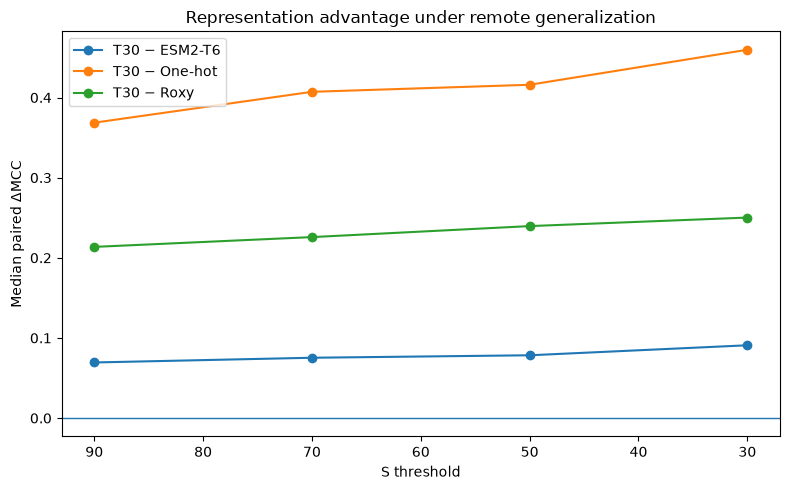

In [14]:
if len(t30_deltas):
    fig, ax = plt.subplots(figsize=(8, 5))

    for comparator, grp in gap_by_S.groupby("comparator"):
        g = grp.set_index("S").reindex(S_LEVELS)

        ax.plot(
            S_LEVELS,
            g["delta_mcc_T30_minus_comparator"],
            marker="o",
            label=f"T30 − {REP_LABEL.get(comparator, comparator)}",
        )

    ax.axhline(0, linewidth=1)
    ax.set_xlabel("S threshold")
    ax.set_ylabel("Median paired ΔMCC")
    ax.set_title("Representation advantage under remote generalization")
    ax.legend()
    ax.invert_xaxis()
    plt.tight_layout()
    plt.show()

# 9. Representation ranks within matched benchmark cells

In [15]:
rank_rows = []

for keys, grp in master.groupby(
    ["task", "R", "S", "algorithm"]
):
    task, r, s, alg = keys

    g = grp[
        ["representation", "mcc"]
    ].dropna().copy()

    if len(g) != len(REPS):
        continue

    g["rank"] = (
        g["mcc"]
        .rank(method="average", ascending=False)
    )

    for rec in g.to_dict("records"):
        rank_rows.append(
            {
                "task": task,
                "R": r,
                "S": s,
                "algorithm": alg,
                "representation": rec["representation"],
                "mcc": rec["mcc"],
                "rank": rec["rank"],
            }
        )

rep_ranks = pd.DataFrame(rank_rows)

rank_summary = (
    rep_ranks.groupby("representation")
    .agg(
        mean_rank=("rank", "mean"),
        median_rank=("rank", "median"),
        first_place_fraction=(
            "rank",
            lambda x: (x == 1).mean(),
        ),
        top2_fraction=(
            "rank",
            lambda x: (x <= 2).mean(),
        ),
    )
    .reindex(REPS)
)

display(rank_summary)

,mean_rank,median_rank,first_place_fraction,top2_fraction
representation,,,,
roxy_48,3.077679,3.0,0.000000,0.012500
onehot_1024,3.902679,4.0,0.000000,0.001786
esm2_t6_8m,1.950893,2.0,0.066071,0.982143
esm2_t30_150m,1.068750,1.0,0.928571,1.000000


# 10. Which representation wins each task?

In [16]:
task_rank_summary = (
    rep_ranks.groupby(["task", "representation"])
    .agg(
        mean_rank=("rank", "mean"),
        median_rank=("rank", "median"),
        first_place_fraction=(
            "rank",
            lambda x: (x == 1).mean(),
        ),
    )
    .reset_index()
)

display(
    task_rank_summary.pivot(
        index="task",
        columns="representation",
        values="mean_rank",
    ).reindex(columns=REPS)
)

representation,roxy_48,onehot_1024,esm2_t6_8m,esm2_t30_150m
task,,,,
global_easy,3.07500,3.92500,2.00000,1.00000
global_hard,3.02500,3.97500,1.80625,1.19375
global_mixed,3.05000,3.95000,2.00000,1.00000
multiclass_clean,3.18750,3.81250,1.92500,1.07500
subtype_depolymerase,3.18750,3.78750,1.86250,1.16250
subtype_endolysin,3.02500,3.97500,2.00000,1.00000
subtype_val,2.99375,3.89375,2.06250,1.05000


# 11. Strict-corner performance: R30_S30

In [17]:
strict_corner = master[
    master["R"].eq(30)
    & master["S"].eq(30)
].copy()

strict_summary = (
    strict_corner.groupby("representation")
    .agg(
        n=("mcc", "size"),
        mcc_mean=("mcc", "mean"),
        mcc_median=("mcc", "median"),
        mcc_q25=("mcc", lambda x: x.quantile(0.25)),
        mcc_min=("mcc", "min"),
    )
    .reindex(REPS)
)

display(strict_summary)

,n,mcc_mean,mcc_median,mcc_q25,mcc_min
representation,,,,,
roxy_48,35,0.619182,0.615759,0.521032,0.146572
onehot_1024,35,0.406507,0.390374,0.236961,0.000000
esm2_t6_8m,35,0.771769,0.781808,0.703014,0.418898
esm2_t30_150m,35,0.859844,0.880510,0.841125,0.541012


The strict corner is especially useful because it asks which representation remains useful after both redundancy control and remote-homology evaluation have become stringent.

# 12. Worst-case performance across each complete R×S surface

In [18]:
worst_case = (
    master.groupby(
        ["task", "representation", "algorithm"]
    )
    .agg(
        mcc_worst=("mcc", "min"),
        mcc_median=("mcc", "median"),
        mcc_best=("mcc", "max"),
        mcc_range=("mcc", lambda x: x.max() - x.min()),
    )
    .reset_index()
)

worst_rep = (
    worst_case.groupby("representation")
    .agg(
        worst_case_mean=("mcc_worst", "mean"),
        worst_case_median=("mcc_worst", "median"),
        median_surface_mcc=("mcc_median", "median"),
        median_surface_range=("mcc_range", "median"),
    )
    .reindex(REPS)
)

display(worst_rep)

,worst_case_mean,worst_case_median,median_surface_mcc,median_surface_range
representation,,,,
roxy_48,0.559412,0.569411,0.651957,0.145188
onehot_1024,0.375438,0.380187,0.446350,0.195817
esm2_t6_8m,0.690147,0.758396,0.828340,0.117530
esm2_t30_150m,0.817120,0.853675,0.900628,0.092574


# 13. Robustness to redundancy reduction

In [19]:
r_extreme_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm", "S"]
):
    task, rep, alg, s = keys

    lookup = dict(zip(grp["R"].astype(int), grp["mcc"]))

    if 90 in lookup and 30 in lookup:
        r_extreme_rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "S": s,
                "delta_R30_minus_R90": (
                    lookup[30] - lookup[90]
                ),
            }
        )

r_robustness = pd.DataFrame(r_extreme_rows)

display(
    r_robustness.groupby("representation")[
        "delta_R30_minus_R90"
    ]
    .agg(
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_negative=lambda x: (x < 0).mean(),
    )
    .reindex(REPS)
)

,mean,median,median_abs,fraction_negative
representation,,,,
roxy_48,-0.068453,-0.077351,0.086618,0.785714
onehot_1024,-0.121581,-0.095149,0.098644,0.850000
esm2_t6_8m,-0.051633,-0.056965,0.083029,0.800000
esm2_t30_150m,-0.051018,-0.056807,0.062409,0.850000


# 14. Robustness to remote-homology separation

In [20]:
s_extreme_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm", "R"]
):
    task, rep, alg, r = keys

    lookup = dict(zip(grp["S"].astype(int), grp["mcc"]))

    if 90 in lookup and 30 in lookup:
        s_extreme_rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "R": r,
                "delta_S30_minus_S90": (
                    lookup[30] - lookup[90]
                ),
            }
        )

s_robustness = pd.DataFrame(s_extreme_rows)

display(
    s_robustness.groupby("representation")[
        "delta_S30_minus_S90"
    ]
    .agg(
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_negative=lambda x: (x < 0).mean(),
    )
    .reindex(REPS)
)

,mean,median,median_abs,fraction_negative
representation,,,,
roxy_48,-0.033859,-0.020911,0.035806,0.692857
onehot_1024,-0.066185,-0.033905,0.037725,0.721429
esm2_t6_8m,-0.036658,-0.017782,0.020476,0.685714
esm2_t30_150m,-0.018073,-0.011272,0.015238,0.735714


Together, worst-case MCC, redundancy robustness, and homology robustness distinguish:

- representations that merely perform well in permissive settings;
- representations that remain strong when related support is removed;
- representations that retain performance on more remote test proteins.

# 15. PLM family versus classical representations

In [21]:
PLM_REPS = [
    r for r in REPS
    if r.startswith("esm2_")
]

CLASSICAL_REPS = [
    r for r in REPS
    if r not in PLM_REPS
]

family_rows = []

for keys, grp in master.groupby(
    ["task", "R", "S", "algorithm"]
):
    task, r, s, alg = keys

    plm = grp[
        grp["representation"].isin(PLM_REPS)
    ]["mcc"].dropna()

    classical = grp[
        grp["representation"].isin(CLASSICAL_REPS)
    ]["mcc"].dropna()

    if len(plm) and len(classical):
        family_rows.append(
            {
                "task": task,
                "R": r,
                "S": s,
                "algorithm": alg,
                "plm_mean_mcc": plm.mean(),
                "classical_mean_mcc": classical.mean(),
                "delta_plm_minus_classical": (
                    plm.mean() - classical.mean()
                ),
            }
        )

family_gap = pd.DataFrame(family_rows)

display(
    family_gap["delta_plm_minus_classical"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .to_frame("PLM − classical")
)

print(
    "Fraction PLM-family advantage > 0:",
    (family_gap["delta_plm_minus_classical"] > 0).mean(),
)

,PLM − classical
count,560.000000
mean,0.284007
median,0.292674
std,0.135859
min,0.068957
max,0.714583


Fraction PLM-family advantage > 0: 1.0


In [22]:
display(
    family_gap.groupby("task")[
        "delta_plm_minus_classical"
    ]
    .agg(["mean", "median", "std", "min", "max"])
)

,mean,median,std,min,max
task,,,,,
global_easy,0.329861,0.325913,0.057681,0.173124,0.458553
global_hard,0.122653,0.119528,0.024661,0.069272,0.184186
global_mixed,0.326907,0.323624,0.058625,0.173630,0.448341
multiclass_clean,0.164499,0.159101,0.033414,0.106689,0.242447
subtype_depolymerase,0.234414,0.191715,0.114019,0.082653,0.496879
subtype_endolysin,0.357546,0.366386,0.065215,0.165587,0.515798
subtype_val,0.452166,0.471949,0.153100,0.068957,0.714583


The family-level result is supportive only. The primary representation evidence remains the paired model-by-model contrasts, because averaging T6/T30 or Roxy/one-hot hides differences within each family.

# 16. AP-skill representation comparison for binary tasks

In [23]:
if "ap_skill" in master.columns:
    ap_binary = master[
        master["task"].isin(BINARY_TASKS)
    ].copy()

    ap_rep = (
        ap_binary.groupby("representation")[
            "ap_skill"
        ]
        .agg(["mean", "median", "std", "min", "max"])
        .reindex(REPS)
    )

    display(ap_rep)

    ap_pairs = paired_representation_table(
        ap_binary,
        "ap_skill",
    )

    ap_pair_summary = (
        ap_pairs.groupby(
            ["representation_A", "representation_B"]
        )["delta_B_minus_A"]
        .agg(
            n="size",
            mean="mean",
            median="median",
            fraction_positive=lambda x: (x > 0).mean(),
        )
        .reset_index()
    )

    display(ap_pair_summary)

,mean,median,std,min,max
representation,,,,,
roxy_48,0.695691,0.746061,0.224122,0.058212,0.989179
onehot_1024,0.529210,0.496727,0.260145,0.002559,0.978099
esm2_t6_8m,0.859761,0.891274,0.127497,0.050139,0.994694
esm2_t30_150m,0.937201,0.953687,0.059333,0.619874,0.995356


,representation_A,representation_B,n,mean,median,fraction_positive
0,esm2_t6_8m,esm2_t30_150m,480,0.077440,0.062617,0.943750
1,onehot_1024,esm2_t30_150m,480,0.407991,0.454377,1.000000
2,onehot_1024,esm2_t6_8m,480,0.330551,0.368911,0.993750
3,roxy_48,esm2_t30_150m,480,0.241510,0.211161,1.000000
4,roxy_48,esm2_t6_8m,480,0.164070,0.139740,0.995833
5,roxy_48,onehot_1024,480,-0.166481,-0.171243,0.102083


# 17. Multiclass macro-F1 representation comparison

In [24]:
if "macro_f1" in master.columns:
    multi = master[
        master["task"].eq("multiclass_clean")
    ].copy()

    if multi["macro_f1"].notna().any():
        multi_rep = (
            multi.groupby("representation")[
                "macro_f1"
            ]
            .agg(["mean", "median", "std", "min", "max"])
            .reindex(REPS)
        )

        display(multi_rep)

        multi_pairs = paired_representation_table(
            multi,
            "macro_f1",
        )

        display(
            multi_pairs.groupby(
                ["representation_A", "representation_B"]
            )["delta_B_minus_A"]
            .agg(
                n="size",
                mean="mean",
                median="median",
                fraction_positive=lambda x: (x > 0).mean(),
            )
            .reset_index()
        )

,mean,median,std,min,max
representation,,,,,
roxy_48,0.678565,0.671821,0.051931,0.590416,0.791691
onehot_1024,0.580779,0.569566,0.050397,0.480304,0.772366
esm2_t6_8m,0.766393,0.769482,0.050256,0.660782,0.860607
esm2_t30_150m,0.808428,0.811221,0.046212,0.684704,0.906658


,representation_A,representation_B,n,mean,median,fraction_positive
0,esm2_t6_8m,esm2_t30_150m,80,0.042035,0.043420,0.875
1,onehot_1024,esm2_t30_150m,80,0.227649,0.226706,1.000
2,onehot_1024,esm2_t6_8m,80,0.185614,0.189070,1.000
3,roxy_48,esm2_t30_150m,80,0.129863,0.125259,1.000
4,roxy_48,esm2_t6_8m,80,0.087828,0.086724,0.975
5,roxy_48,onehot_1024,80,-0.097786,-0.098343,0.025


# 18. Representation stability across tasks

A representation should not be considered broadly preferable only because it dominates one easy task.

Summarize rank and worst-case behavior within each biological task.

In [25]:
task_stability = (
    worst_case.groupby(["task", "representation"])
    .agg(
        median_worst_case_mcc=("mcc_worst", "median"),
        median_surface_mcc=("mcc_median", "median"),
        median_surface_range=("mcc_range", "median"),
    )
    .reset_index()
)

display(
    task_stability.pivot(
        index="task",
        columns="representation",
        values="median_worst_case_mcc",
    ).reindex(columns=REPS)
)

representation,roxy_48,onehot_1024,esm2_t6_8m,esm2_t30_150m
task,,,,
global_easy,0.569305,0.356526,0.751080,0.869458
global_hard,0.796338,0.698670,0.898290,0.899887
global_mixed,0.569411,0.380148,0.749415,0.864446
multiclass_clean,0.707320,0.606133,0.788346,0.829019
subtype_depolymerase,0.768598,0.572382,0.834227,0.855756
subtype_endolysin,0.493643,0.283704,0.704346,0.859624
subtype_val,0.177054,0.000000,0.227179,0.622757


# 19. Compact evidence synthesis

RQ6 should be considered complete if it establishes:

1. the overall representation hierarchy;
2. paired effect sizes rather than only pooled medians;
3. win/tie/loss consistency;
4. task dependence;
5. representation behavior under strict R/S conditions;
6. rank consistency across matched cells;
7. worst-case generalization;
8. robustness to R and S;
9. agreement with AP skill / macro-F1.

The deeper **T30 versus T6 scaling question is RQ7**, so RQ6 should not overinterpret that contrast as a mechanistic scaling law.

In [26]:
summary_rows = []

for rep in REPS:
    g = master[
        master["representation"].eq(rep)
    ]

    ranks = rep_ranks[
        rep_ranks["representation"].eq(rep)
    ]

    wc = worst_case[
        worst_case["representation"].eq(rep)
    ]

    rr = r_robustness[
        r_robustness["representation"].eq(rep)
    ]

    sr = s_robustness[
        s_robustness["representation"].eq(rep)
    ]

    summary_rows.append(
        {
            "representation": rep,
            "mcc_median": g["mcc"].median(),
            "mcc_mean": g["mcc"].mean(),
            "mean_rank": ranks["rank"].mean(),
            "first_place_fraction": (
                (ranks["rank"] == 1).mean()
            ),
            "median_worst_case_mcc": (
                wc["mcc_worst"].median()
            ),
            "median_R90_to_R30_delta": (
                rr["delta_R30_minus_R90"].median()
            ),
            "median_abs_R90_to_R30_delta": (
                rr["delta_R30_minus_R90"].abs().median()
            ),
            "median_S90_to_S30_delta": (
                sr["delta_S30_minus_S90"].median()
            ),
            "median_abs_S90_to_S30_delta": (
                sr["delta_S30_minus_S90"].abs().median()
            ),
        }
    )

rq6_summary = (
    pd.DataFrame(summary_rows)
    .set_index("representation")
    .reindex(REPS)
    .reset_index()
)

display(rq6_summary)

,representation,mcc_median,mcc_mean,mean_rank,first_place_fraction,median_worst_case_mcc,median_R90_to_R30_delta,median_abs_R90_to_R30_delta,median_S90_to_S30_delta,median_abs_S90_to_S30_delta
0,roxy_48,0.675438,0.649787,3.077679,0.000000,0.569411,-0.077351,0.086618,-0.020911,0.035806
1,onehot_1024,0.496018,0.463568,3.902679,0.000000,0.380187,-0.095149,0.098644,-0.033905,0.037725
2,esm2_t6_8m,0.828667,0.798397,1.950893,0.066071,0.758396,-0.056965,0.083029,-0.017782,0.020476
3,esm2_t30_150m,0.902239,0.882970,1.068750,0.928571,0.853675,-0.056807,0.062409,-0.011272,0.015238


In [27]:
SUMMARY_PATH = CACHE_DIR / "rq6_representation_summary.tsv"
PAIRWISE_PATH = CACHE_DIR / "rq6_representation_pairwise_mcc.tsv"
RANK_PATH = CACHE_DIR / "rq6_representation_ranks.tsv"
T30_PATH = CACHE_DIR / "rq6_t30_matched_gains.tsv"
WORST_PATH = CACHE_DIR / "rq6_representation_worst_case.tsv"
RROB_PATH = CACHE_DIR / "rq6_representation_R_robustness.tsv"
SROB_PATH = CACHE_DIR / "rq6_representation_S_robustness.tsv"
FAMILY_PATH = CACHE_DIR / "rq6_plm_vs_classical.tsv"

rq6_summary.to_csv(SUMMARY_PATH, sep="\t", index=False)
rep_mcc.to_csv(PAIRWISE_PATH, sep="\t", index=False)
rep_ranks.to_csv(RANK_PATH, sep="\t", index=False)
t30_deltas.to_csv(T30_PATH, sep="\t", index=False)
worst_case.to_csv(WORST_PATH, sep="\t", index=False)
r_robustness.to_csv(RROB_PATH, sep="\t", index=False)
s_robustness.to_csv(SROB_PATH, sep="\t", index=False)
family_gap.to_csv(FAMILY_PATH, sep="\t", index=False)

print("Saved:")
for p in [
    SUMMARY_PATH,
    PAIRWISE_PATH,
    RANK_PATH,
    T30_PATH,
    WORST_PATH,
    RROB_PATH,
    SROB_PATH,
    FAMILY_PATH,
]:
    print(" ", p)

Saved:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq6_representation_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq6_representation_pairwise_mcc.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq6_representation_ranks.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq6_t30_matched_gains.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq6_representation_worst_case.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq6_representation_R_robustness.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_proje

## Interpretation guardrails

- Representation comparisons are paired because the biological test cell is identical across representations.
- Do not infer that PLMs learn a specific biological mechanism from performance alone.
- Do not interpret T30–T6 differences here as a complete model-scaling conclusion; that is RQ7.
- Do not let VAL dominate pooled summaries because its positive support is small in stringent regimes.
- Do not rank representations by permissive-condition MCC alone; paired gains, strict-corner performance, robustness, and worst-case performance are all required.
- Compute efficiency is intentionally deferred to the dedicated compute analysis.